# Discovering Stellar Streams in Gaia DR3
## Unsupervised learning in Galactic phase space

This notebook accompanies the supplied project proposal. It inspects the **executed synthetic demonstration** and explains the real Gaia pipeline. It does not claim real stream discoveries. The bundled trails are toy correlated trajectories rather than N-body simulations or named Galactic streams.

Run all cells after installing the project. A later opt-in cell can repeat the complete pipeline in a new folder.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Image, HTML

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/stellar_streams').exists()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter in the extracted Gaia_Stellar_Streams_Project folder')
sys.path.insert(0, str(ROOT / 'src'))
from stellar_streams.config import load_config
from stellar_streams.preprocessing import quality_filter, to_phase_space, FEATURES
from stellar_streams.pipeline import run_pipeline
from stellar_streams.synthetic import make_demo
config = load_config(ROOT / 'configs/default.yaml')
DATA = ROOT / 'outputs/demo/data'
RESULTS = ROOT / 'outputs/demo/results'
summary = json.loads((RESULTS / 'summary.json').read_text())
print('Data kind:', summary['data_kind'])
print('Executed Python:', summary['python'])
print('Configuration:'); display(pd.Series(config.to_dict()).to_frame('value'))

Data kind: synthetic_toy
Executed Python: 3.12.14
Configuration:


,value
seed,42
ruwe_max,1.4
parallax_snr_min,5.0
rv_error_max,5.0
halo_z_min_kpc,3.0
chunk_size,50000
max_stars,100000
sampling,error
n_neighbors,30
n_components,3


## 1. Gaia-like input and quality cuts
Real input comes from `gaiadr3.gaia_source` through `astroquery`. The synthetic generator reverses Astropy's transform and adds small independent errors. Truth and reference memberships are separate files.

The strict cuts are RUWE < 1.4, positive parallax, parallax S/N > 5, and radial-velocity error < 5 km/s. Numeric inputs must also be finite. The project retains source IDs as decimal strings to avoid precision loss.

In [2]:
raw = pd.read_csv(DATA / 'demo_gaia.csv', dtype={'source_id': 'string'})
clean = quality_filter(raw, config)
print(f'Raw: {len(raw):,}; quality survivors: {len(clean):,}')
display(raw.head())

Raw: 4,320; quality survivors: 4,200


,source_id,ra,dec,parallax,parallax_error,parallax_over_error,pmra,pmdec,radial_velocity,radial_velocity_error,ruwe,phot_g_mean_mag
0,900000000000000000,204.885515,-37.913914,0.052835,0.001066,49.580778,-2.142897,-2.366359,176.631002,0.5,1.8,11.305370
1,900000000000000001,266.901278,8.524673,0.047513,0.000928,51.211015,-0.039871,-2.284582,-292.734908,0.5,1.8,11.320283
2,900000000000000002,119.651064,-5.356439,0.043820,0.000893,49.050083,-0.553193,-2.169940,215.379102,0.5,1.8,13.976893
3,900000000000000003,246.549001,-43.856264,0.095450,0.001924,49.609459,-1.410295,-4.106374,80.123248,0.5,1.8,14.635459
4,900000000000000004,225.850483,-81.627313,0.072106,0.001451,49.693854,-1.862121,3.322119,-160.091066,0.5,1.8,14.709906


## 2. Transform to six physical features
For positive parallax in milliarcseconds, the baseline approximation is $d_{kpc}=1/\varpi_{mas}$. `SkyCoord` uses RA, Dec, distance, `pm_ra_cosdec`, `pm_dec`, and radial velocity. The explicit Galactocentric frame is saved in each run summary.

This baseline does not correct the parallax zero point or propagate correlated astrometric uncertainties. Those changes are needed before making robust astrophysical claims.

In [3]:
phase = to_phase_space(clean)
halo = phase.loc[phase.z_kpc.abs() > config.halo_z_min_kpc]
assert len(halo) == summary['selection']['halo_rows']
print('Halo selection:', len(halo), 'stars')
display(halo[FEATURES].describe().round(3))
display(pd.Series(summary['galactocentric_frame']).to_frame('frame value'))

Halo selection: 3313 stars


,x_kpc,y_kpc,z_kpc,vx_kms,vy_kms,vz_kms
count,3313.000,3313.000,3313.000,3313.000,3313.000,3313.000
mean,0.040,0.364,0.411,5.264,13.983,-5.695
std,11.044,11.374,10.075,134.521,134.296,126.871
min,-36.559,-49.403,-32.354,-548.114,-512.693,-467.488
25%,-8.378,-8.074,-7.948,-100.307,-95.631,-80.654
50%,1.183,1.592,3.789,18.065,20.921,-18.749
75%,6.451,8.773,8.439,96.891,105.753,65.514
max,39.703,38.087,36.795,581.460,450.761,445.871


,frame value
galcen_distance_kpc,8.122
z_sun_pc,20.8
solar_velocity_kms,"[12.9, 245.6, 7.78]"
galcen_ra_deg,266.4051
galcen_dec_deg,-28.936175
roll_deg,0.0


## 3. Robust scaling, UMAP and HDBSCAN
Only the six physical features enter the learner. Each is centered on the median and divided by its interquartile range. Positions and velocities can then be weighted separately.

The delivered demonstration uses 3 UMAP components, 30 neighbors, min_dist = 0, and HDBSCAN leaf selection with minimum cluster size 120 and minimum samples 20. Leaf selection was chosen after a small synthetic parameter comparison. These settings are not calibrated for real Gaia streams.

A first EOM baseline merged two toy trails with the background. The complete comparison is retained in `docs/toy_parameter_comparison.csv`. This illustrates why clustering hyperparameters and original-space diagnostics matter.

Density candidates: 7
Noise fraction: 30.0%
Candidates supported by direct 6D overlap: 3


,cluster_id,n_members,mean_membership_strength,cluster_persistence,seed_jaccard_mean,direct_6d_best_jaccard,original_6d_supported,position_elongation,velocity_dispersion_3d_kms,status,median_x_kpc,median_y_kpc,median_z_kpc,median_vx_kms,median_vy_kms,median_vz_kms
0,0,255,0.813,0.617,0.996,0.940,True,1.734,24.154,unvalidated_density_candidate,-10.004,4.050,7.002,99.060,-109.418,49.329
1,1,255,0.853,0.565,0.988,0.877,True,1.849,32.120,unvalidated_density_candidate,3.920,9.972,9.972,60.004,160.450,-79.897
2,2,272,0.910,0.266,0.934,0.834,True,2.298,41.630,unvalidated_density_candidate,6.022,-9.177,-8.044,-139.876,68.378,-55.156
3,3,476,0.905,0.094,0.841,0.004,False,2.590,224.159,unvalidated_density_candidate,-2.582,-1.919,8.918,4.700,19.651,114.744
4,4,308,0.964,0.067,0.736,0.023,False,2.301,204.611,unvalidated_density_candidate,3.132,-0.125,8.284,-6.269,-17.954,-115.496
5,5,225,0.999,0.014,0.455,0.004,False,2.564,186.305,unvalidated_density_candidate,-0.080,3.439,-7.424,10.242,-27.234,-158.567
6,6,529,0.963,0.069,0.572,0.028,False,2.074,202.927,unvalidated_density_candidate,1.088,1.024,-9.106,44.119,27.637,56.858


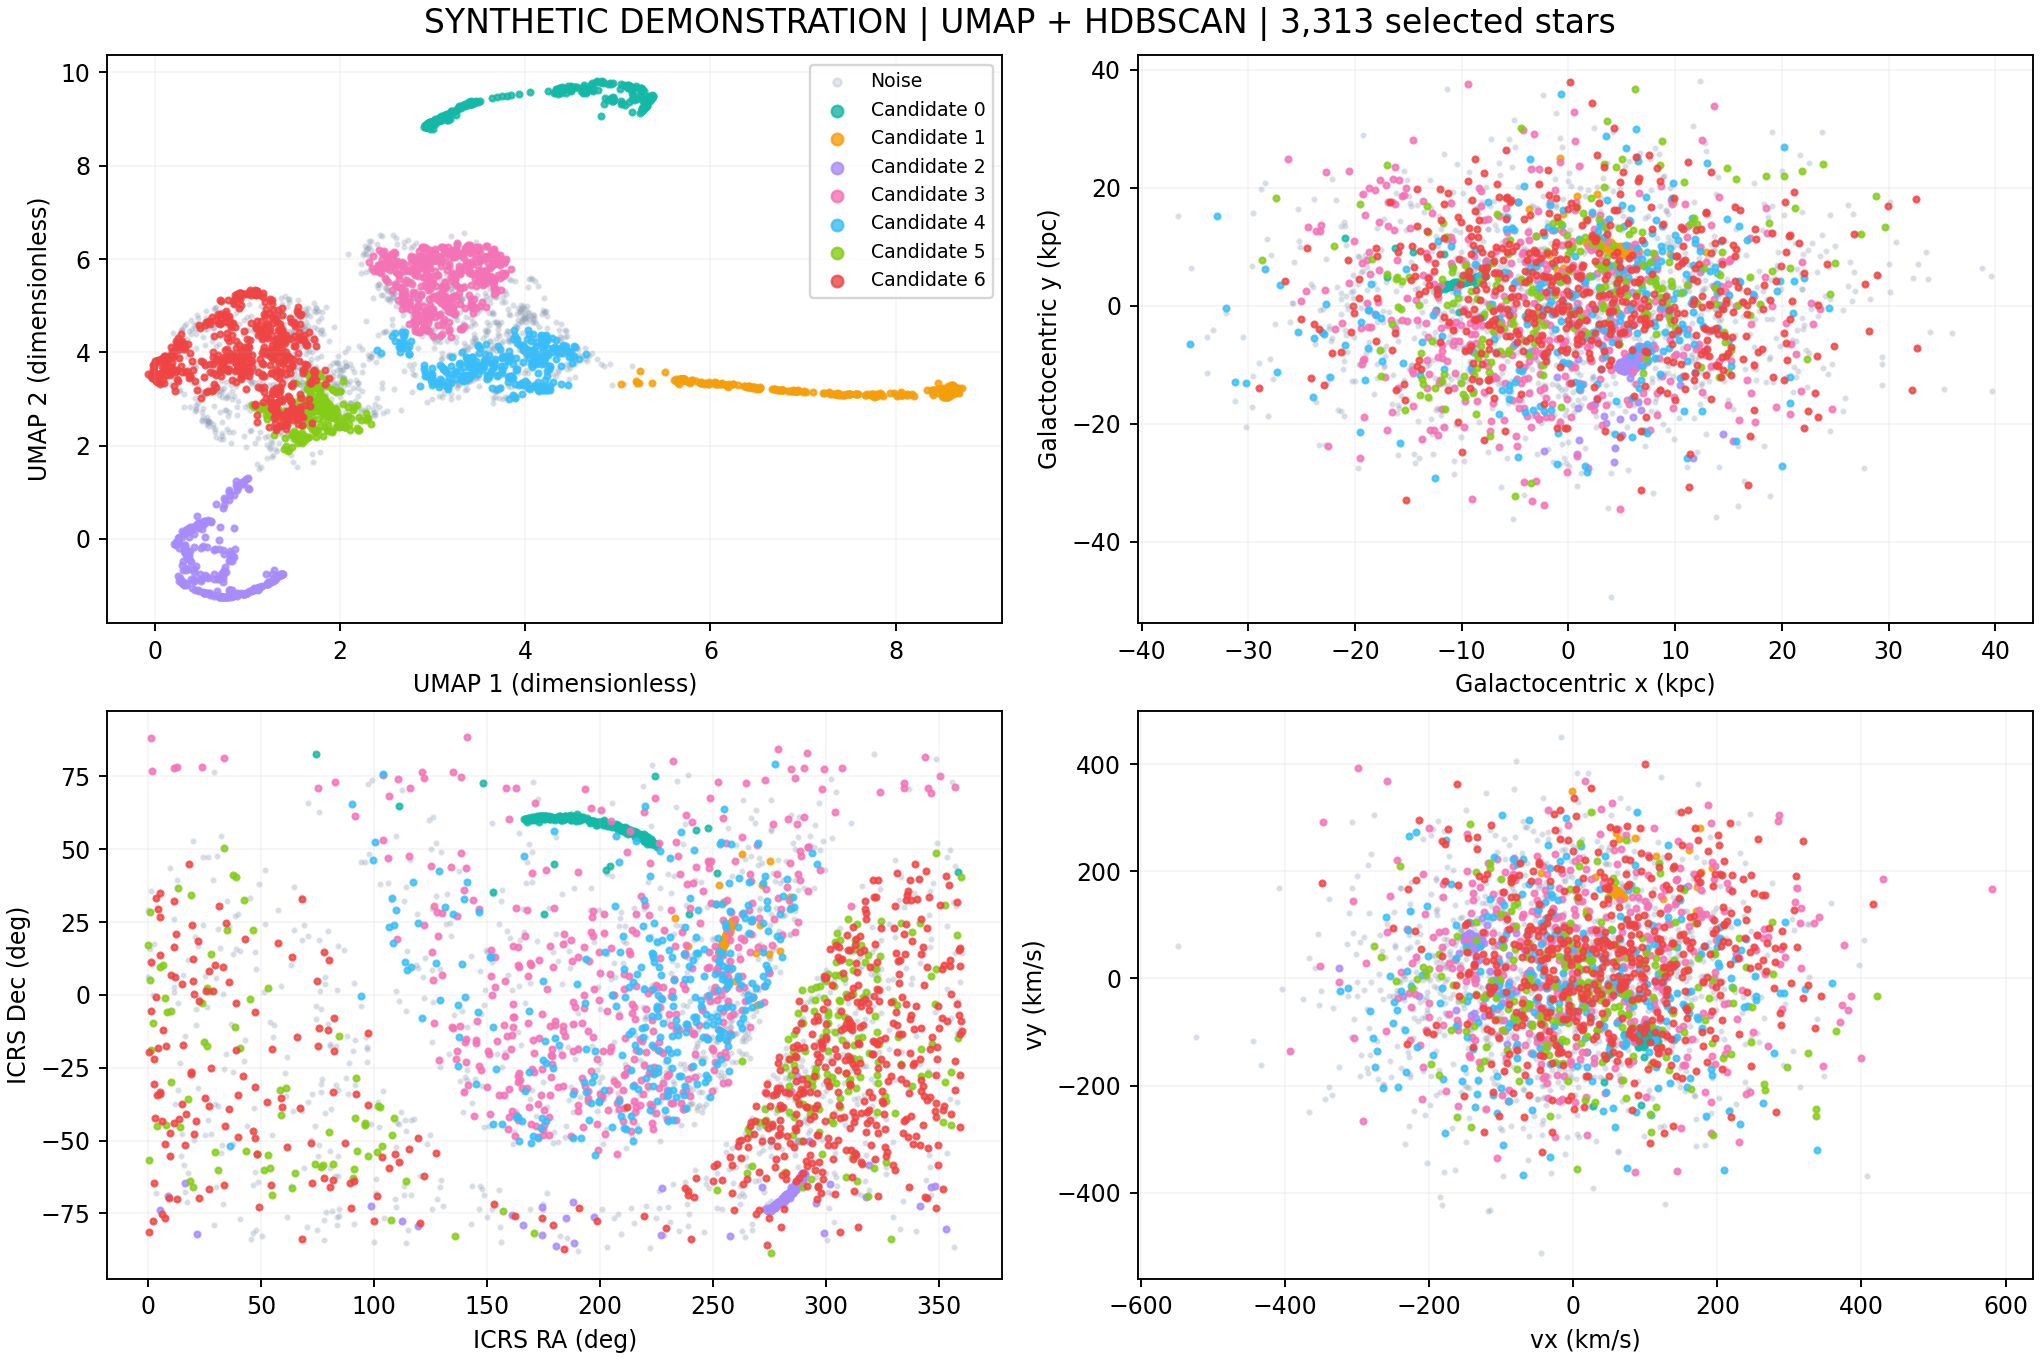

In [4]:
assigned = pd.read_csv(RESULTS / 'assigned_stars.csv', dtype={'source_id': 'string'})
catalog = pd.read_csv(RESULTS / 'candidate_catalog.csv')
print('Density candidates:', summary['n_clusters'])
print('Noise fraction:', f"{summary['noise_fraction']:.1%}")
print('Candidates supported by direct 6D overlap:', summary['original_6d_supported_candidates'])
display(catalog.round(3))
display(Image(filename=str(RESULTS / 'phase_space_overview.png')))

## 4. Evaluate toy recovery without leaking labels
The adjusted Rand index includes field stars as a single truth class. Per-trail precision and recall use the best overlapping predicted cluster; they can reveal merges and splits. The field false-assignment fraction is essential: assigning every trail star is not sufficient when most field stars are also assigned.

In [5]:
evaluation = json.loads((RESULTS / 'toy_evaluation.json').read_text())
metrics = {k: v for k, v in evaluation.items() if k not in ['trail_recovery']}
display(pd.Series(metrics).to_frame('measured value'))
display(pd.DataFrame(evaluation['trail_recovery']).round(4))

,measured value
data_kind,synthetic_toy_only
selected_rows,3313
adjusted_rand_index_including_field,0.203636
trail_member_clustered_fraction,1.0
field_false_assignment_fraction,0.617046


,truth_label,best_cluster_id,selected_truth_members,overlap,best_cluster_recall,best_cluster_precision
0,0,0,240,240,1.0,0.9412
1,1,2,240,240,1.0,0.8824
2,2,1,240,240,1.0,0.9412


## 5. Stability and the original-6D control
UMAP seeds 43 and 44 are compared against seed 42 using best membership Jaccard overlap. Direct HDBSCAN on the same scaled 6D features provides an embedding-free control.

A direct-6D Jaccard of at least 0.5 is only a descriptive support flag. Groups remain unvalidated candidates. The seed checks do not perturb measurement errors, and numeric cluster IDs have no stable meaning across runs.

In [6]:
stability = pd.read_csv(RESULTS / 'seed_stability.csv')
display(stability.round(3))
display(catalog[['cluster_id', 'n_members', 'seed_jaccard_mean',
                 'direct_6d_best_jaccard', 'original_6d_supported',
                 'velocity_dispersion_3d_kms']].round(3))

,cluster_id,seed,best_membership_jaccard
0,0,43,0.996
1,1,43,0.992
2,2,43,0.956
3,3,43,0.849
4,4,43,0.738
5,5,43,0.332
6,6,43,0.527
7,0,44,0.996
8,1,44,0.984
9,2,44,0.912


,cluster_id,n_members,seed_jaccard_mean,direct_6d_best_jaccard,original_6d_supported,velocity_dispersion_3d_kms
0,0,255,0.996,0.940,True,24.154
1,1,255,0.988,0.877,True,32.120
2,2,272,0.934,0.834,True,41.630
3,3,476,0.841,0.004,False,224.159
4,4,308,0.736,0.023,False,204.611
5,5,225,0.455,0.004,False,186.305
6,6,529,0.572,0.028,False,202.927


## 6. Reference catalog comparison
The bundled reference contains **synthetic** trail members only. For real use, supply an independently obtained membership CSV with `source_id,stream_name` and verify Gaia DR3 ID compatibility.

Cluster overlap fraction is not physical purity if the reference is incomplete. Recovery denominators are given for both the selected sample and the entire supplied reference. Exact-ID agreement supports investigation; it does not by itself validate a stream.

In [7]:
overlap = pd.read_csv(RESULTS / 'reference_overlap.csv')
display(overlap.round(3))
comparison = pd.read_csv(ROOT / 'docs/toy_parameter_comparison.csv')
display(comparison.round(3))

,cluster_id,stream_name,matched_members,cluster_size,reference_overlap_fraction,reference_members_in_selected_sample,reference_recovery_in_selected_sample,reference_full_catalog_members,reference_recovery_full_catalog
0,0,SYNTHETIC_TRAIL_1,240,255,0.941,240,1.0,240,1.0
1,1,SYNTHETIC_TRAIL_3,240,255,0.941,240,1.0,240,1.0
2,2,SYNTHETIC_TRAIL_2,240,272,0.882,240,1.0,240,1.0


,method,min_cluster_size,min_samples,n_clusters,noise_fraction,field_false_assignment_fraction,ari,trail_1_precision,trail_1_recall,trail_2_precision,trail_2_recall,trail_3_precision,trail_3_recall
0,eom,60,20,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
1,eom,60,80,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
2,eom,120,20,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
3,eom,120,80,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
4,eom,180,20,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
5,eom,180,80,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
6,eom,220,20,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
7,eom,220,80,2,0.000,1.000,0.403,0.941,1.000,0.078,1.000,0.078,1.000
8,leaf,60,20,14,0.424,0.471,0.242,0.971,0.550,0.979,0.588,0.960,0.604
9,leaf,60,80,7,0.305,0.626,0.268,0.959,0.488,0.960,0.908,0.964,1.000


## 7. Repeat the full offline experiment
Set the flag below to True to generate a fresh synthetic dataset and execute every pipeline stage. A unique output folder preserves the bundled results. The first UMAP run may take longer because of compilation.

In [8]:
RUN_NEW_EXPERIMENT = False
if RUN_NEW_EXPERIMENT:
    from datetime import datetime
    experiment = ROOT / 'outputs' / ('notebook_run_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
    make_demo(experiment / 'data', seed=config.seed)
    run_pipeline(experiment / 'data/demo_gaia.csv', experiment / 'results', config,
                 reference=experiment / 'data/demo_reference.csv',
                 truth=experiment / 'data/demo_truth.csv', data_kind='synthetic_toy')
else:
    print('Bundled results loaded. Enable RUN_NEW_EXPERIMENT to repeat the pipeline.')

Bundled results loaded. Enable RUN_NEW_EXPERIMENT to repeat the pipeline.


## 8. Query and analyze real Gaia DR3
Use these commands in a terminal from the project folder (internet required):

```bash
python -m stellar_streams.cli fetch --output data/gaia_dr3.csv --max-rows 0 --random-index-max 50000000 --config configs/default.yaml
python -m stellar_streams.cli run --input data/gaia_dr3.csv --output outputs/gaia_run --data-kind gaia_dr3 --config configs/default.yaml
```

The archive downloader uses source-ID pagination and caches each completed page. A positive `max-rows` truncates a sky-ordered sample; use a complete random-index subset for full-sky sampling. The local halo cut is applied after the physical transformation.

CSV preprocessing is chunked, but UMAP and HDBSCAN use RAM. The default maximum is 100,000 eligible stars. Exceeding it raises an error; explicit uniform sampling is configurable and reported.

Live ESA archive execution remains unverified in the delivery environment. The query/resume logic was tested against mocked responses.

## Interpretation and next steps

- Inspect groups in physical positions, velocities and the sky, rather than only the embedding.
- Test independent synthetic seeds, field-only controls, parameter changes and uncertainty resampling before relying on recovery rates.
- Improve distances and model Gaia selection effects for distant halo stars.
- Compare with independent catalogs; follow up with orbital and chemical evidence.
- Scale using physically motivated partitions with overlap and explicit reconciliation; separate shard labels cannot simply be concatenated.

Open `outputs/demo/results/explorer.html` directly for the interactive offline view. The PDF report and the README describe results, limits and future work.